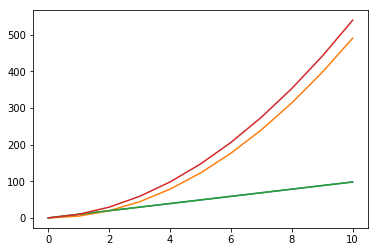

,vs,ys',dvs,dys',t
0,0.0,0.0,0.0,0.0,0
1,9.8,4.9,9.8,9.8,1
2,19.6,19.6,19.6,29.4,2
3,29.4,44.1,29.4,58.8,3
4,39.2,78.4,39.2,98.0,4
5,49.0,122.5,49.0,147.0,5
6,58.8,176.4,58.8,205.8,6
7,68.6,240.1,68.6,274.4,7
8,78.4,313.6,78.4,352.8,8
9,88.2,396.9,88.2,441.0,9


In [49]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


def v(t):
    g = 9.8
    v0 = 0
    return v0 + g * t

def y(t):
    y0 = 0
    g = 9.8
    v0 = 0
    return y0 + v0*t + 1/2*g*t*t

def vn_1(vn, an, dt):
    return vn + an * dt


def yn_1(yn, vn_1, dt):
    return yn + vn_1 * dt

vs = [v(0)]
ys = [y(0)]


for t in range(1, 11):
    vs.append(v(t))
    ys.append(y(t))

v = 0
y = 0
dvs = [v]
dys = [y]
for t in range(1, 11):
    v = vn_1(v, 9.8, 1)
    dvs.append(v)
    y = yn_1(y, v, 1)
    dys.append(y)

    
fig, ax = plt.subplots()

ax.plot(vs)
ax.plot(ys)

ax.plot(dvs)
ax.plot(dys)
plt.show()
    
data = pd.DataFrame({
    "vs": vs,   
    "ys'": ys,
    "dvs": dvs,   
    "dys'": dys,
    "t": list(range(11)),
})

data


In [99]:
import itertools
ytrue = np.array([0.0, 0.075, 0.260, 0.525, 0.870, 1.27, 1.73, 2.23, 2.77, 3.35])
t = [-0.132, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

def v1(k, v):
    g = 9.8
    return g * (1- k * v/g)

def yn_1(yn, vn_1, dt):
    return yn + vn_1 * dt



bester = 101000
bestk = 0.01

for k in np.arange(bestk, 100, 0.01):
    ypred = []
    v = 0
    y = 0
    
    ypred.append(y)
    
    for j in range(1, len(t)):
        v = v1(k, v)
        y = yn_1(j, v, t[j]-t[j-1])

        ypred.append(y)


        
    nber = min(bester,  np.mean(np.abs(ytrue - np.array(ypred))))   
    if bester != nber:
        bestk = k
    bester = nb
    
bestk



1.3800000000000001